# 12 Klasifikasi Multi-Label

Satu teks bisa punya beberapa label sekaligus. Contoh: jenis ujaran kebencian di Twitter.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

ISI_SETELAH_EDA

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** satu teks bisa masuk lebih dari satu kategori, misalnya komentar MBG yang membahas
korupsi sekaligus keracunan. Metriknya biasanya macro-F1 atau micro-F1 per label.

**Yang perlu diganti kalau datanya beda:**
- `load_data`, `TEXT_COL`, `LABEL_COLS`.
- Kalau tiap label punya polaritas, misalnya positif atau negatif per aspek, pakai folder `13`.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya TF-IDF, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
HOLDOUT_SHARE = 0.2
TEXT_COL = "Tweet"
LABEL_COLS = [
    "Abusive",
    "HS_Individual",
    "HS_Group",
    "HS_Religion",
    "HS_Race",
    "HS_Physical",
    "HS_Gender",
    "HS_Other",
]

SETTINGS = {
    "cepat": {"folds": 3, "epochs": 4, "model_runs": [("indobertweet", SEED)]},
    "penuh": {
        "folds": 5,
        "epochs": 5,
        "model_runs": [("indobertweet", SEED), ("indobert", SEED), ("indobertweet", SEED + 1)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'folds': 5, 'epochs': 5, 'model_runs': [('indobertweet', 42), ('indobert', 42), ('indobertweet', 43)]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Metrik, interval noise, dan pencatat hasil.** Metrik diuji dulu pada contoh yang jawabannya
dihitung manual. `record` mencatat skor OOF dan skor holdout untuk tiap pendekatan.

In [6]:
from sklearn.metrics import f1_score  # noqa: E402
from sklearn.model_selection import StratifiedGroupKFold  # noqa: E402


def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


assert abs(macro_f1([0, 0, 1, 1], [0, 1, 1, 1]) - (2 / 3 + 0.8) / 2) < 1e-9


def bootstrap_interval(y_true, y_pred, score_fn=macro_f1, n_boot: int = 300) -> str:
    """Interval 95%. Selisih di dalam interval ini belum tentu perbaikan nyata."""
    rng = np.random.default_rng(SEED)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(y_true), len(y_true))
        scores.append(score_fn(y_true[pick], y_pred[pick]))
    return f"{np.percentile(scores, 2.5):.3f}-{np.percentile(scores, 97.5):.3f}"


def make_folds(target, groups, n_folds: int) -> np.ndarray:
    """StratifiedGroupKFold: duplikat tidak lintas fold, proporsi kelas terjaga."""
    splitter = StratifiedGroupKFold(n_folds, shuffle=True, random_state=SEED)
    folds = np.zeros(len(target), dtype=int)
    for fold, (_, val_idx) in enumerate(splitter.split(np.zeros(len(target)), target, groups)):
        folds[val_idx] = fold
    return folds


results: list[dict] = []


def record(name: str, oof_pred, holdout_pred, score_fn=macro_f1) -> None:
    """Catat skor OOF dan holdout. Holdout hanya untuk laporan, bukan untuk memilih model."""
    results.append(
        {
            "model": name,
            "oof": round(score_fn(y, oof_pred), 4),
            "oof_ci95": bootstrap_interval(y, oof_pred, score_fn),
            "holdout": round(score_fn(y_holdout, holdout_pred), 4),
        }
    )
    print(results[-1])

**Model dengan cross-validation.** `cv_tfidf` adalah baseline word dan char TF-IDF + regresi
logistik, sedangkan `cv_transformer` melatih tiap kombinasi model dan seed di semua fold. Hasilnya
probabilitas OOF dan rata-rata probabilitas holdout.

In [7]:
from scipy.sparse import hstack  # noqa: E402
from sklearn.multiclass import OneVsRestClassifier  # noqa: E402


def cv_tfidf(train_texts, target, holdout_texts, folds, multilabel=False):
    """Baseline TF-IDF. Vektorisasi difit di dalam fold supaya tidak bocor."""
    target = np.asarray(target)
    shape = target.shape[1] if multilabel else int(target.max()) + 1
    oof = np.zeros((len(target), shape))
    holdout = np.zeros((len(holdout_texts), shape))
    train_texts = pd.Series(list(train_texts))
    holdout_series = pd.Series(list(holdout_texts))
    for fold in np.unique(folds):
        fit, val = folds != fold, folds == fold
        word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)
        x_fit = hstack([word.fit_transform(train_texts[fit]), char.fit_transform(train_texts[fit])])
        base = LogisticRegression(C=3.0, max_iter=2000, class_weight="balanced")
        model = OneVsRestClassifier(base) if multilabel else base
        model.fit(x_fit.tocsr(), target[fit])
        for mask_texts, store, where in (
            (train_texts[val], oof, val),
            (holdout_series, holdout, None),
        ):
            x_pred = hstack([word.transform(mask_texts), char.transform(mask_texts)]).tocsr()
            probs = model.predict_proba(x_pred)
            if where is None:
                store += probs / len(np.unique(folds))
            else:
                store[where] = probs
    return oof, holdout


def cv_transformer(
    train_texts,
    target,
    holdout_texts,
    folds,
    model_runs,
    epochs,
    problem="ce",
    balanced=True,
    max_len=128,
):
    """Latih tiap (model, seed) di semua fold, lalu rata-ratakan probabilitasnya."""
    target = np.asarray(target)
    train_texts = np.array(list(train_texts), dtype=object)
    holdout_texts = list(holdout_texts)
    n_out = (
        target.shape[1] if problem == "bce" else (1 if problem == "mse" else int(target.max()) + 1)
    )
    oof = np.zeros((len(target), n_out))
    holdout = np.zeros((len(holdout_texts), n_out))
    n_folds = len(np.unique(folds))
    for model_name, seed in model_runs:
        for fold in range(n_folds):
            fit, val = folds != fold, folds == fold
            weights = None
            if problem == "ce" and balanced:
                weights = len(target[fit]) / (n_out * np.bincount(target[fit], minlength=n_out))
            elif problem == "bce" and balanced:
                positives = np.maximum(target[fit].sum(0), 1)
                weights = np.clip((len(target[fit]) - positives) / positives, 1, 20)
            pred_val, pred_hold = train_predict(
                model_name,
                train_texts[fit].tolist(),
                target[fit],
                [train_texts[val].tolist(), holdout_texts],
                problem=problem,
                num_labels=n_out if problem != "bce" else None,
                class_weights=weights,
                epochs=epochs,
                seed=seed + fold,
                max_len=max_len,
            )
            oof[val] += pred_val.reshape(val.sum(), -1) / len(model_runs)
            holdout += pred_hold.reshape(len(holdout_texts), -1) / (n_folds * len(model_runs))
    return oof, holdout

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [8]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

## 4. EDA

Muat data dan sisihkan holdout yang hanya dipakai untuk laporan akhir.

In [9]:
from sklearn.model_selection import train_test_split  # noqa: E402


def load_data() -> pd.DataFrame:
    frame = pd.read_csv(find_file("data.csv"), encoding="latin-1")
    frame = frame.sample(n=min(N_ROWS, len(frame)), random_state=SEED).reset_index(drop=True)
    return frame[[TEXT_COL] + LABEL_COLS]


data = load_data()
train, holdout = train_test_split(data, test_size=HOLDOUT_SHARE, random_state=SEED)
train, holdout = train.reset_index(drop=True), holdout.reset_index(drop=True)
print(f"latih={len(train)} | holdout={len(holdout)}")
text_profile(train[TEXT_COL])

latih=4000 | holdout=1000


baris                4000.0
kosong                  0.0
duplikat_persis_%       0.5
kata_median            15.0
kata_p95               38.0
kata_maks              52.0
ada_url_%               0.0
ada_emoji_%             0.0
dtype: float64

Jumlah positif per label, jumlah label per baris, dan label mana yang sering muncul bersama.

proporsi positif per label: {'Abusive': 0.385, 'HS_Individual': 0.269, 'HS_Group': 0.151, 'HS_Religion': 0.054, 'HS_Race': 0.044, 'HS_Physical': 0.021, 'HS_Gender': 0.02, 'HS_Other': 0.29}
jumlah label per baris: {0: 1765, 1: 557, 2: 679, 3: 970, 4: 29}


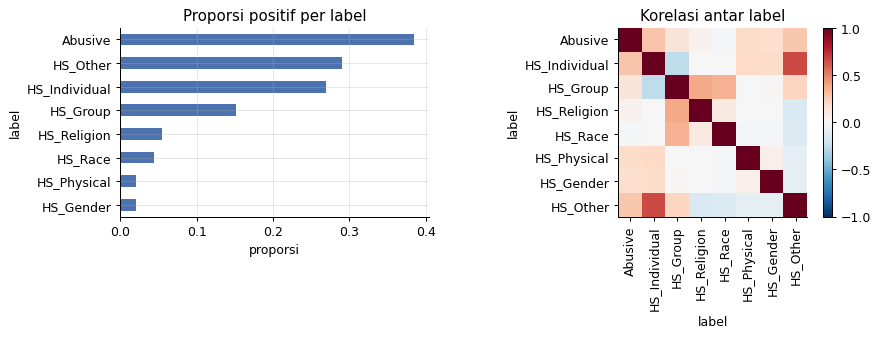

In [10]:
prevalence = train[LABEL_COLS].mean().round(3)
per_row = train[LABEL_COLS].sum(axis=1)
print("proporsi positif per label:", prevalence.to_dict())
print("jumlah label per baris:", per_row.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
prevalence.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title="Proporsi positif per label", xlabel="proporsi", ylabel="label")
correlation = train[LABEL_COLS].corr().to_numpy()
image = axes[1].imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ticks = range(len(LABEL_COLS))
axes[1].set(
    xticks=ticks,
    yticks=ticks,
    xticklabels=LABEL_COLS,
    yticklabels=LABEL_COLS,
    title="Korelasi antar label",
    xlabel="label",
    ylabel="label",
)
axes[1].tick_params(axis="x", rotation=90)
axes[1].grid(False)
fig.colorbar(image)
plt.tight_layout()
plt.show()

**Temuan dan keputusan**

ISI_SETELAH_EDA

## 5. Preprocessing

Token anonimisasi dibuang, kata kasar tetap dipertahankan karena menjadi sinyal utama.

In [11]:
TOKEN_RE = re.compile(r"\b(USER|RT|URL)\b|\\n")
BYTES_RE = re.compile(r"(?:\\x[0-9a-f]{2})+")


def decode_bytes(match: re.Match) -> str:
    """Data ini menyimpan emoji sebagai teks byte, misalnya \\xf0\\x9f\\x98\\xa0. Kembalikan jadi emoji."""
    return " " + bytes.fromhex(match.group(0).replace("\\x", "")).decode("utf-8", "ignore") + " "


def preprocess(text: str) -> str:
    return clean_text(TOKEN_RE.sub(" ", BYTES_RE.sub(decode_bytes, str(text))))


train["clean"] = train[TEXT_COL].map(preprocess)
holdout["clean"] = holdout[TEXT_COL].map(preprocess)
train["group"] = near_duplicate_groups(train["clean"].tolist())
y = train[LABEL_COLS].to_numpy()
y_holdout = holdout[LABEL_COLS].to_numpy()
print(f"grup near-duplicate: {train['group'].nunique()} dari {len(train)} baris")

grup near-duplicate: 3957 dari 4000 baris


## 6. Validasi

Fold distratifikasi menurut jumlah label per baris, dan grup near-duplicate tidak lintas fold. Metrik
utama macro-F1 antar label, dengan micro-F1 sebagai pembanding.

In [12]:
def macro_f1_labels(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


def micro_f1_labels(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="micro", zero_division=0))


_true = np.array([[1, 0], [0, 1]])
assert macro_f1_labels(_true, _true) == 1.0
assert abs(micro_f1_labels(_true, np.array([[1, 1], [0, 1]])) - 0.8) < 1e-9

folds = make_folds(np.minimum(y.sum(1), 3), train["group"], SETTINGS["folds"])
print("baris per fold:", np.bincount(folds).tolist())

baris per fold: [800, 802, 803, 798, 797]


## 7. Baseline

Tebak semua negatif sebagai batas bawah, lalu TF-IDF + regresi logistik per label dengan threshold 0,5.

In [13]:
record("semua_negatif", np.zeros_like(y), np.zeros_like(y_holdout), macro_f1_labels)
with stage("baseline_tfidf"):
    oof_tfidf, hold_tfidf = cv_tfidf(train["clean"], y, holdout["clean"], folds, multilabel=True)
record("tfidf_lr", (oof_tfidf >= 0.5).astype(int), (hold_tfidf >= 0.5).astype(int), macro_f1_labels)

{'model': 'semua_negatif', 'oof': 0.0, 'oof_ci95': '0.000-0.000', 'holdout': 0.0}


[waktu] baseline_tfidf: 35 detik


{'model': 'tfidf_lr', 'oof': 0.6156, 'oof_ci95': '0.592-0.635', 'holdout': 0.6094}


## 8. Model Utama

Satu transformer dengan satu keluaran per label, jadi model bisa memanfaatkan hubungan antar label.
Loss BCE memakai `pos_weight`, karena tanpa itu label langka seperti `HS_Gender` (2%) tidak terlatih.

In [14]:
with stage("transformer"):
    if USE_PRETRAINED:
        oof_main, hold_main = cv_transformer(
            train["clean"],
            y,
            holdout["clean"],
            folds,
            SETTINGS["model_runs"],
            SETTINGS["epochs"],
            problem="bce",
        )
    else:
        oof_main, hold_main = oof_tfidf, hold_tfidf
record(
    "model_utama", (oof_main >= 0.5).astype(int), (hold_main >= 0.5).astype(int), macro_f1_labels
)

[waktu] transformer: 1790 detik


{'model': 'model_utama', 'oof': 0.6139, 'oof_ci95': '0.600-0.627', 'holdout': 0.6263}


## 9. Post-processing

Threshold per label, karena label langka hampir tidak pernah mencapai 0,5. Skor OOF dihitung nested.
Tiga kandidat dibandingkan: TF-IDF, transformer, dan rata-rata keduanya. Yang dipakai adalah kandidat dengan
skor OOF nested tertinggi.

In [15]:
def label_thresholds(scores: np.ndarray, target: np.ndarray) -> np.ndarray:
    grid = np.arange(0.03, 0.91, 0.01)
    best = []
    for col in range(target.shape[1]):
        values = [f1_score(target[:, col], scores[:, col] >= t, zero_division=0) for t in grid]
        best.append(grid[int(np.argmax(values))])
    return np.array(best)


def nested_thresholded(scores: np.ndarray) -> np.ndarray:
    output = np.zeros_like(y)
    for fold in np.unique(folds):
        fit = folds != fold
        output[~fit] = scores[~fit] >= label_thresholds(scores[fit], y[fit])
    return output


candidates = {
    "tfidf": (oof_tfidf, hold_tfidf),
    "transformer": (oof_main, hold_main),
    "rata_rata": ((oof_tfidf + oof_main) / 2, (hold_tfidf + hold_main) / 2),
}
scored = {}
for name, (oof_scores, hold_scores) in candidates.items():
    scored[name] = nested_thresholded(oof_scores)
    record(
        f"{name}_plus_threshold",
        scored[name],
        (hold_scores >= label_thresholds(oof_scores, y)).astype(int),
        macro_f1_labels,
    )

best_name = max(scored, key=lambda n: macro_f1_labels(y, scored[n]))
best_oof, best_hold = candidates[best_name]
oof_decision = scored[best_name]
thresholds = label_thresholds(best_oof, y)
hold_decision = (best_hold >= thresholds).astype(int)
print("dipilih dari OOF:", best_name, "| micro-F1 OOF:", round(micro_f1_labels(y, oof_decision), 4))

{'model': 'tfidf_plus_threshold', 'oof': 0.6183, 'oof_ci95': '0.597-0.638', 'holdout': 0.61}


{'model': 'transformer_plus_threshold', 'oof': 0.6446, 'oof_ci95': '0.626-0.662', 'holdout': 0.6873}


{'model': 'rata_rata_plus_threshold', 'oof': 0.6713, 'oof_ci95': '0.650-0.692', 'holdout': 0.6894}


dipilih dari OOF: rata_rata | micro-F1 OOF: 0.7754


## 10. Post-analysis

**Tabel perbandingan.**

In [16]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,oof,oof_ci95,holdout
0,semua_negatif,0.0000,0.000-0.000,0.0000
1,tfidf_lr,0.6156,0.592-0.635,0.6094
2,model_utama,0.6139,0.600-0.627,0.6263
3,tfidf_plus_threshold,0.6183,0.597-0.638,0.6100
4,transformer_plus_threshold,0.6446,0.626-0.662,0.6873
5,rata_rata_plus_threshold,0.6713,0.650-0.692,0.6894


**Skor per label.** Label langka biasanya paling lemah, dan bisa jadi datanya memang tidak cukup.

In [17]:
per_label = pd.DataFrame(
    {
        "positif_latih": y.sum(0),
        "threshold": thresholds.round(2),
        "f1_oof": f1_score(y, oof_decision, average=None, zero_division=0).round(3),
        "f1_holdout": f1_score(y_holdout, hold_decision, average=None, zero_division=0).round(3),
    },
    index=LABEL_COLS,
).sort_values("positif_latih", ascending=False)
per_label

,positif_latih,threshold,f1_oof,f1_holdout
Abusive,1541,0.51,0.884,0.911
HS_Other,1160,0.53,0.794,0.762
HS_Individual,1075,0.45,0.741,0.712
HS_Group,603,0.49,0.658,0.671
HS_Religion,218,0.57,0.705,0.637
HS_Race,177,0.63,0.774,0.783
HS_Physical,85,0.49,0.383,0.556
HS_Gender,82,0.48,0.431,0.485


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [18]:
pd.DataFrame(hold_decision, columns=LABEL_COLS).rename_axis("id").to_csv(
    RESULT_DIR / "submission.csv"
)
pd.DataFrame(best_oof, columns=LABEL_COLS).assign(fold=folds).to_csv(
    RESULT_DIR / "oof.csv", index=False
)
run_summary(
    "multi_label",
    len(data),
    {r["model"]: {"oof": r["oof"], "holdout": r["holdout"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=multi_label mode=penuh n_rows=5000 total_detik=1875 gpu=True
{
 "semua_negatif": {
  "oof": 0.0,
  "holdout": 0.0
 },
 "tfidf_lr": {
  "oof": 0.6156,
  "holdout": 0.6094
 },
 "model_utama": {
  "oof": 0.6139,
  "holdout": 0.6263
 },
 "tfidf_plus_threshold": {
  "oof": 0.6183,
  "holdout": 0.61
 },
 "transformer_plus_threshold": {
  "oof": 0.6446,
  "holdout": 0.6873
 },
 "rata_rata_plus_threshold": {
  "oof": 0.6713,
  "holdout": 0.6894
 }
}


**Poin untuk presentasi**

ISI_SETELAH_EDA